In [391]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
import copy

from diffusion_mlp_cnn.models.utils import Data
from diffusion_mlp_cnn.models.MLP import MLPDiffusionRegressor

In [392]:
plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

# Load data

### Training and single-step validation data

In [393]:
size = 1925
initializations = ["gaussian", "uniform", "cosine"]
training_data = Data(
    initializations,
    path="../datasets/training_size_" + str(size) + "/training_data",
    model_type="MLP"
)
print(f"Input training data shape (N_samples, Nx): "
      f"{training_data.X_numpy.shape}")
print(f"Output training data shape (N_samples, Nx): "
      f"{training_data.Y_numpy.shape}")
print(f"Training data dtype (input, output): "
      f"({training_data.X.dtype}, {training_data.Y.dtype})")

Input training data shape (N_samples, Nx): (1925, 201)
Output training data shape (N_samples, Nx): (1925, 201)
Training data dtype (input, output): (torch.float32, torch.float32)


In [394]:
validation_data = Data(
    initializations,
    path="../datasets/training_size_" + str(size) + "/validation_data",
    model_type="MLP"
)
print(f"Input single step validation data shape (N_samples, Nx): "
      f"{validation_data.X_numpy.shape}")
print(f"Output single step validation data shape (N_samples, Nx): "
      f"{validation_data.Y_numpy.shape}")
print(f"single step validation data dtype (input, output): "
      f"({validation_data.X.dtype}, {validation_data.Y.dtype})")

Input single step validation data shape (N_samples, Nx): (350, 201)
Output single step validation data shape (N_samples, Nx): (350, 201)
single step validation data dtype (input, output): (torch.float32, torch.float32)


### Full time series data

Initializations: Gaussian, uniform block and cosine

# Load trained MLP

In [395]:
os.makedirs("figures", exist_ok=True)

In [396]:
epochs = {}
training_MSE_loss = {}
training_L2_error = {}
validation_L2_error = {}
mlp_models = {}
for width in [128, 256, 512]:
    epochs.update({width: {}})
    training_MSE_loss.update({width: {}})
    training_L2_error.update({width: {}})
    validation_L2_error.update({width: {}})
    mlp_models.update({width: {}})
    for depth in [2, 4, 8]:
        epochs[width].update({depth: {}})
        training_MSE_loss[width].update({depth: {}})
        training_L2_error[width].update({depth: {}})
        validation_L2_error[width].update({depth: {}})
        mlp_models[width].update({depth: {}})
        for activation in ["relu", "tanh"]:
            perf_data = np.loadtxt(
                "training_performance/mlp_" + activation + "_width_" + str(width) +
                "_depth_" + str(depth) + ".txt",
                dtype=np.float32
            )
            epochs[width][depth].update({activation: perf_data[:, 0]})
            training_MSE_loss[width][depth].update({activation: perf_data[:, 1]})
            training_L2_error[width][depth].update({activation: perf_data[:, 2]})
            validation_L2_error[width][depth].update({activation: perf_data[:, 3]})
            model = MLPDiffusionRegressor(
                training_data.Nx,
                width,
                depth,
                activation=activation
            )
            model.load_state_dict(
                torch.load("trained_models/mlp_" + activation + "_width_" + str(width) +
                           "_depth_" + str(depth) + ".pt",
                           map_location="cpu", weights_only=True)
            )
            mlp_models[width][depth].update({activation: model})

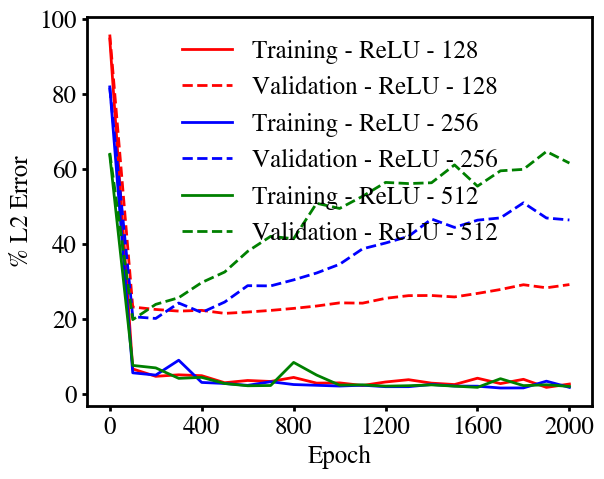

In [397]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs[128][8]["relu"], training_L2_error[128][8]["relu"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training - ReLU - 128")
ax.plot(epochs[128][8]["relu"], validation_L2_error[128][8]["relu"] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Validation - ReLU - 128")
ax.plot(epochs[256][8]["relu"], training_L2_error[256][8]["relu"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Training - ReLU - 256")
ax.plot(epochs[256][8]["relu"], validation_L2_error[256][8]["relu"] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation - ReLU - 256")
ax.plot(epochs[512][8]["relu"], training_L2_error[512][8]["relu"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Training - ReLU - 512")
ax.plot(epochs[512][8]["relu"], validation_L2_error[512][8]["relu"] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Validation - ReLU - 512")
ax.set_xlabel(r"Epoch", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
# plt.savefig("figures/training_performance_mlp_width_relu.pdf")
plt.show()

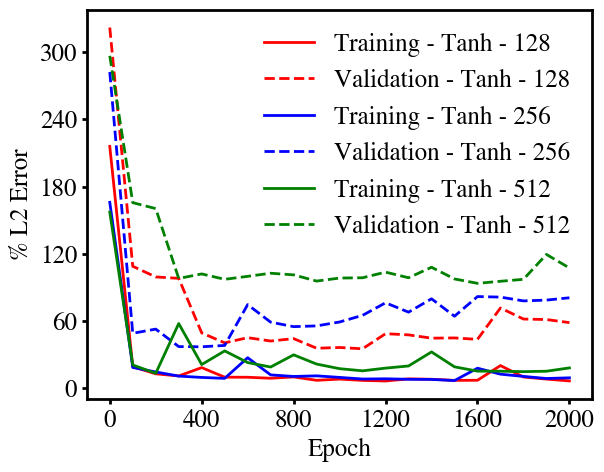

In [398]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs[128][8]["tanh"], training_L2_error[128][8]["tanh"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training - Tanh - 128")
ax.plot(epochs[128][8]["tanh"], validation_L2_error[128][8]["tanh"] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Validation - Tanh - 128")
ax.plot(epochs[256][8]["tanh"], training_L2_error[256][8]["tanh"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Training - Tanh - 256")
ax.plot(epochs[256][8]["tanh"], validation_L2_error[256][8]["tanh"] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation - Tanh - 256")
ax.plot(epochs[512][8]["tanh"], training_L2_error[512][8]["tanh"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Training - Tanh - 512")
ax.plot(epochs[512][8]["tanh"], validation_L2_error[512][8]["tanh"] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Validation - Tanh - 512")
ax.set_xlabel(r"Epoch", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
# plt.savefig("figures/training_performance_mlp_width_relu.pdf")
plt.show()

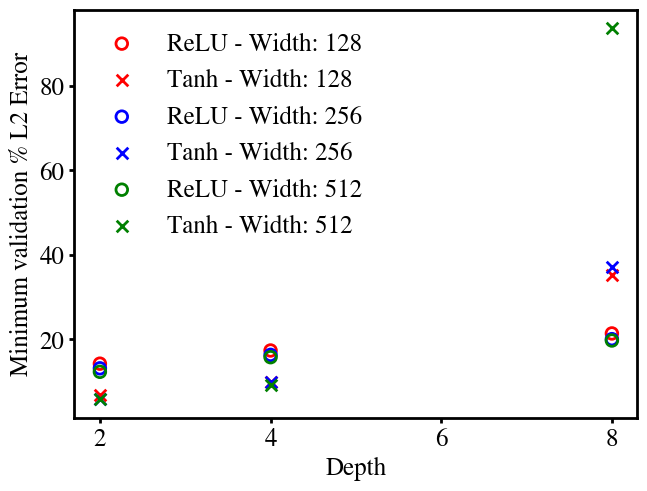

In [399]:
min_errors_relu = {
    128: [],
    256: [],
    512: []
}
min_errors_tanh = copy.deepcopy(min_errors_relu)
depths = [2, 4, 8]
for width in min_errors_relu:
    for depth in depths:
        min_errors_relu[width].append(
            np.min(validation_L2_error[width][depth]["relu"]) *
            100
        )
        min_errors_tanh[width].append(
            np.min(validation_L2_error[width][depth]["tanh"]) *
            100
        )
colors = ["red", "blue", "green"]
fig = plt.figure(2)
ax = fig.add_axes([0.11, 0.14, 0.88, 0.85])
for itr, width in enumerate(min_errors_relu):
    ax.scatter(
        depths,
        min_errors_relu[width],
        label=f"ReLU - Width: {width}",
        s=70,
        marker="o",
        facecolor="none",
        edgecolor=colors[itr],
        linewidth=2
    )
    ax.scatter(
        depths,
        min_errors_tanh[width],
        label=f"Tanh - Width: {width}",
        s=70,
        marker="x",
        color=colors[itr],
        linewidth=2
    )
ax.set_xlabel(r"Depth", fontsize=18)
ax.set_ylabel(r"Minimum validation % L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_mlp_depth_width.pdf")
plt.show()

# Auto-regressive testing

In [400]:
l2_error_time = {}
mass_err_mlp = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
for width in [128, 256, 512]:
    l2_error_time.update({width: {}})
    mass_err_mlp.update({width: {}})
    u_pred.update({width: {}})
    for depth in [2, 4, 8]:
        l2_error_time[width].update({depth: {}})
        mass_err_mlp[width].update({depth: {}})
        u_pred[width].update({depth: {}})
        for activation in ["relu", "tanh"]:
            l2_error_time[width][depth].update({activation: {}})
            mass_err_mlp[width][depth].update({activation: {}})
            u_pred[width][depth].update({activation: {}})
            model = mlp_models[width][depth][activation]
            model.eval()
            with torch.inference_mode():
                for init_type in initializations:
                    data = np.load(
                        "../datasets/training_size_" + str(size) +
                        "/testing_data/" + init_type + ".npz"
                    )
                    u = data["u"]
                    Nx = data["Nx"]
                    snaps = data["snaps"]
                    u_tensor = torch.from_numpy(u)
                    u_pred_tensor = u_tensor.clone().detach()
                    for snap in range(1, u_tensor.shape[0]):
                        u_pred_tensor[snap] = model(
                            u_pred_tensor[snap - 1]
                        )
                    diff = u_pred_tensor.detach().numpy() - u
                    l2_error = np.linalg.norm(diff, axis=1) /\
                        (np.linalg.norm(u, axis=1) + 1e-10)
                    l2_error_time[width][depth][activation].update(
                        {init_type: l2_error}
                    )
                    u_pred[width][depth][activation].update(
                        {init_type: u_pred_tensor.detach().numpy()}
                    )
                    u_fdm.update({init_type: u})
                    mass_fdm = np.sum(u, axis=1)
                    mass_err_fdm.update(
                        {init_type: (mass_fdm - mass_fdm[0]) / mass_fdm[0]}
                    )
                    mass_mlp = np.sum(
                        u_pred[width][depth][activation][init_type], axis=1
                    )
                    mass_err_mlp[width][depth][activation].update(
                        {init_type: (mass_mlp - mass_mlp[0]) / mass_mlp[0]}
                    )
times = np.arange(0, snaps, 1)  # All must have same time dimension

In [401]:
linestyles = ["solid" for _ in range(3)] +\
    ["dashed" for _ in range(3)] +\
    ["dotted" for _ in range(3)]
colors = ["red", "green", "blue"] * 3

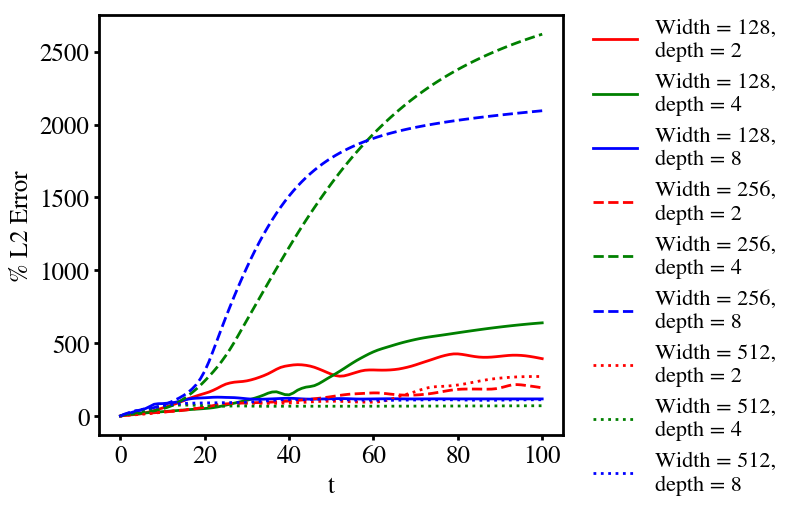

In [402]:
init_type = "gaussian"
activation = "relu"
fig = plt.figure(2, figsize=(8, 5))
ax = fig.add_axes([0.12, 0.14, 0.58, 0.84])
itr = 0
for width in [128, 256, 512]:
    for depth in [2, 4, 8]:
        ax.plot(
            times,
            l2_error_time[width][depth][activation][init_type] * 100,
            linewidth=2,
            color=colors[itr],
            linestyle=linestyles[itr],
            label=f"Width = {width}, \ndepth = {depth}"
        )
        itr += 1
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.04),
    frameon=False,
    fontsize=16
)
plt.savefig("figures/autoregressive_depth_width_relu.pdf")
plt.show()

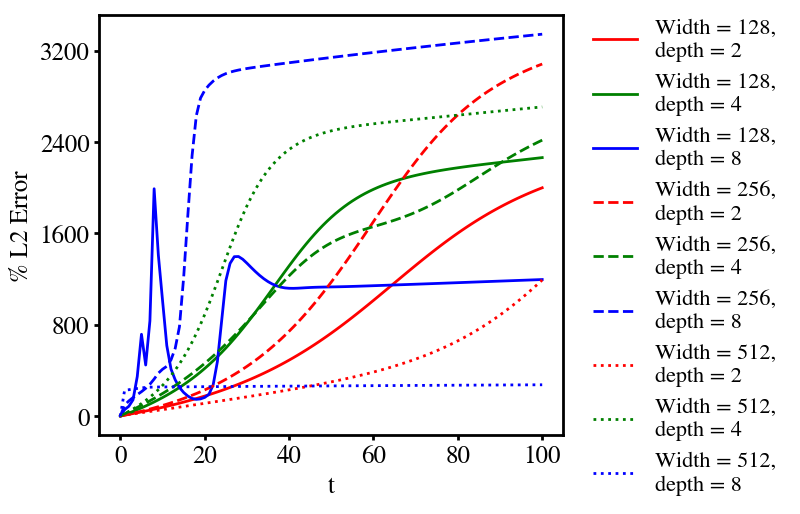

In [403]:
init_type = "gaussian"
activation = "tanh"
fig = plt.figure(2, figsize=(8, 5))
ax = fig.add_axes([0.12, 0.14, 0.58, 0.84])
itr = 0
for width in [128, 256, 512]:
    for depth in [2, 4, 8]:
        ax.plot(
            times,
            l2_error_time[width][depth][activation][init_type] * 100,
            linewidth=2,
            color=colors[itr],
            linestyle=linestyles[itr],
            label=f"Width = {width}, \ndepth = {depth}"
        )
        itr += 1
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.04),
    frameon=False,
    fontsize=16
)
plt.savefig("figures/autoregressive_depth_width_tanh.pdf")
plt.show()